In [41]:
import torch
from torch import nn
from torch.optim import Adam
from torchvision.transforms import transforms
from torch.utils.data import DataLoader, Dataset
from torchinfo import summary
from sklearn.preprocessing import LabelEncoder
import matplotlib.pyplot as plt
from PIL import Image
import pandas as pd
import numpy as np
import os

if torch.cuda.is_available():
    device = 'cuda'
elif torch.backends.mps.is_available():
    device = 'mps'
else:
    device = 'cpu'

# Reading Folders

In [42]:
img_path = []
labels = []

root_file = "/Users/giridharj/Projects/Learning/Pytorch/Animal Faces/animal-faces"

for i in os.listdir(root_file):
    i_dir = os.path.join(root_file, i)
    if not os.path.isdir(i_dir):
        continue
    for label in os.listdir(i_dir):
        label_dir = os.path.join(i_dir, label)
        if not os.path.isdir(label_dir):
            continue
        for img in os.listdir(label_dir):
            if img.startswith('.'):
                continue
            img_path.append(os.path.join(label_dir, img)) # This method is used to split the data and for reading of data
            labels.append(label)

df = pd.DataFrame(zip(img_path, labels), columns=['img_path', 'labels'])
print(df['labels'].unique()) # This is used only when there are limited categories and understand the categories are indentifyable or not.
df.head()


<StringArray>
['cat', 'dog', 'wild']
Length: 3, dtype: str


,img_path,labels
0,/Users/giridharj/Projects/Learning/Pytorch/Ani...,cat
1,/Users/giridharj/Projects/Learning/Pytorch/Ani...,cat
2,/Users/giridharj/Projects/Learning/Pytorch/Ani...,cat
3,/Users/giridharj/Projects/Learning/Pytorch/Ani...,cat
4,/Users/giridharj/Projects/Learning/Pytorch/Ani...,cat


# Splitting Data

In [43]:
train = df.sample(frac=0.7) # This helps us to directly get the DataFrame and here we have taken 0.7(70%) of data for Training.
test = df.drop(train.index) # Here we have taken the rmaining 30% of the Dataset and have dropped the indexes i.e 0,1,2,3,4,....
val = test.sample(frac=0.5) # The Test data that had 30% of the original data has been dividen by half and given to validation i.e 15%
test = test.drop(val.index) # Now we have 15% val and 15% test

print(train.shape)
print(val.shape)
print(test.shape)

(11291, 2)
(2420, 2)
(2419, 2)


# Creating Objects

In [44]:
label_encode = LabelEncoder()
label_encode.fit(df['labels']) # We have stored the value of Lables i.e Cat = 0, Dog = 1, Wild = 2 (This is the Example it can be in any order)

transform = transforms.Compose([ #Transform is used to convert all the images in the same data_type, size, etc
    transforms.Resize((128,128)), # Images gets converted into size of 128 x 128
    transforms.ToTensor(), # Then it gets converted into tensor so as to train model
    transforms.ConvertImageDtype(torch.float)
])

In [45]:
class CustImgData(Dataset):
    def __init__(self, dataframe, transform = None):
        self.dataframe = dataframe
        self.transform = transform
        self.labels = torch.tensor(label_encode.transform(dataframe['labels'])).to(device) # Here the pyTorch converts the strings of Labels to int Wild, Cat, Dog -> 0, 1, 2

    def __len__(self):
        return self.dataframe.shape[0]

    def __getitem__(self, index):
        img_path = self.dataframe.iloc[index, 0] # 1st we are taking the image row by row
        label = self.labels[index]

        img = Image.open(img_path).convert('RGB') # once we reach the path the image is opened.

        if self.transform:
            img = self.transform(img).to(device) # Since we made a transform object all the properties of the transform will be executed

        return img, label

# Storing Data
We have stored the data in Train, Val, Test Variables

In [46]:
train_Dataset = CustImgData(dataframe = train, transform = transform)
val_Dataset = CustImgData(dataframe = val, transform = transform)
test_Dataset = CustImgData(dataframe = test, transform = transform)

In [47]:
train_Dataset.__getitem__(2) # here we have loaded the data in the train, test, val variable


(tensor([[[0.5647, 0.5647, 0.5686,  ..., 0.4784, 0.4667, 0.4745],
          [0.5451, 0.5490, 0.5529,  ..., 0.4784, 0.4588, 0.4667],
          [0.5176, 0.5255, 0.5412,  ..., 0.4745, 0.4667, 0.4706],
          ...,
          [0.5804, 0.5608, 0.5451,  ..., 0.6667, 0.6039, 0.6353],
          [0.5961, 0.5647, 0.5608,  ..., 0.6706, 0.6078, 0.6039],
          [0.5922, 0.5647, 0.5490,  ..., 0.6392, 0.6392, 0.6078]],
 
         [[0.5529, 0.5569, 0.5686,  ..., 0.4627, 0.4510, 0.4588],
          [0.5294, 0.5412, 0.5529,  ..., 0.4667, 0.4471, 0.4549],
          [0.5020, 0.5216, 0.5412,  ..., 0.4627, 0.4549, 0.4588],
          ...,
          [0.5843, 0.5608, 0.5412,  ..., 0.6157, 0.5608, 0.5529],
          [0.5843, 0.5451, 0.5255,  ..., 0.6314, 0.5725, 0.5137],
          [0.5529, 0.5098, 0.4745,  ..., 0.6196, 0.6275, 0.5294]],
 
         [[0.5176, 0.5294, 0.5451,  ..., 0.4118, 0.4000, 0.4039],
          [0.4980, 0.5137, 0.5294,  ..., 0.4039, 0.3843, 0.3922],
          [0.4706, 0.4902, 0.5216,  ...,

In [48]:
label_encode.inverse_transform([0]) # using this function we can Identify what int consist of what type of animal for eg we have 0 -> Cat, 1 -> Dot, 2 -> Wild.

array(['cat'], dtype=object)

# Visualization

Every Time we run this command to visualise the images we get different O/P

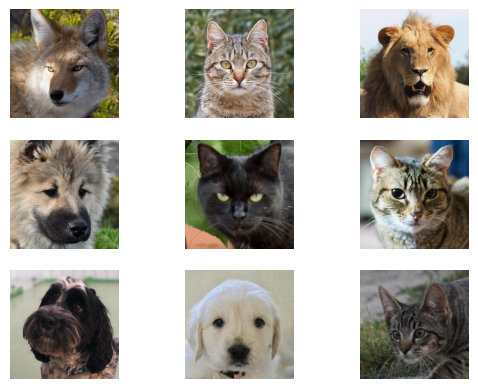

In [49]:
n_rows = 3
n_cols = 3

f, axarr = plt.subplots(n_rows, n_cols)

for row in range(n_rows):
    for col in range(n_cols):
        img = Image.open(df.sample(n = 1)['img_path'].iloc[0]).convert("RGB")
        axarr[row, col].imshow(img)
        axarr[row, col].axis('off')

plt.show()

# Setting Hyper Parameters

In [50]:
LR = 1e-4
Batch_Size = 16
Epochs = 10

In [51]:
train_loader = DataLoader(train_Dataset, Batch_Size, shuffle= True)
val_loader = DataLoader(val_Dataset, Batch_Size, shuffle= True)
test_loader = DataLoader(test_Dataset, Batch_Size, shuffle= True)

# Building up the CNN Layer

In [55]:
class Net(nn.Module):
    def __init__(self):
        super().__init__()

        self.conv1 = nn.Conv2d(3, 32, kernel_size= 3, padding= 1) # We have 3 I/P channel because we are dealing with a RGB Image. If we had a Greyscale image we would have I/P feature 1.
        self.conv2 = nn.Conv2d(32, 64, kernel_size= 3, padding= 1) # Padding is used so that when the size of the img changes it does not lose its feature for the next Convolution layer.
        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding= 1)

        self.pooling = nn.MaxPool2d(2,2)

        self.relu = nn.ReLU()

        self.flatten = nn.Flatten()

        self.linear = nn.Linear((128*16*16), 128)

        self.output = nn.Linear(128, len(df['labels'].unique()))

    def forward(self, x): 
        x = self.conv1(x) # (32, 128, 128)
        x = self.pooling(x) # (32, 64, 64)
        x = self.relu(x)

        x = self.conv2(x) # (64, 64, 64)
        x = self.pooling(x) # (64, 32, 32)
        x = self.relu(x)

        x = self.conv3(x) # (128, 32, 32)
        x = self.pooling(x) # (128, 16, 16)
        x = self.relu(x)

        x = self.flatten(x)
        x = self.linear(x)
        x = self.relu(x)
        x = self.output(x)

        return x

# Creating Network

In [56]:
model = Net().to(device)

In [57]:
summary(model, input_size= (1, 3,128,128), device= device) # Here we have given the batch-size, then the I/P Channel and then the size.

Layer (type:depth-idx)                   Output Shape              Param #
Net                                      [1, 3]                    --
├─Conv2d: 1-1                            [1, 32, 128, 128]         896
├─MaxPool2d: 1-2                         [1, 32, 64, 64]           --
├─ReLU: 1-3                              [1, 32, 64, 64]           --
├─Conv2d: 1-4                            [1, 64, 64, 64]           18,496
├─MaxPool2d: 1-5                         [1, 64, 32, 32]           --
├─ReLU: 1-6                              [1, 64, 32, 32]           --
├─Conv2d: 1-7                            [1, 128, 32, 32]          73,856
├─MaxPool2d: 1-8                         [1, 128, 16, 16]          --
├─ReLU: 1-9                              [1, 128, 16, 16]          --
├─Flatten: 1-10                          [1, 32768]                --
├─Linear: 1-11                           [1, 128]                  4,194,432
├─ReLU: 1-12                             [1, 128]                  --

# Defining Loss and Optimizer

In [58]:
criterion = nn.CrossEntropyLoss()
optimizer = Adam(model.parameters(), lr= LR)

In [59]:
total_loss_train_plot = []
total_loss_val_plot = []
total_acc_train_plot = []
total_acc_val_plot = []

for epoch in range(Epochs):
    total_acc_train = 0
    total_loss_train = 0
    total_acc_val = 0
    total_loss_val = 0

    model.train()
    for inputs , labels in train_loader:
        optimizer.zero_grad()

        outputs = model(inputs)
        train_loss = criterion(outputs, labels)
        total_loss_train += train_loss.item()

        train_loss.backward()

        train_acc = (torch.argmax(outputs, axis = 1) == labels).sum().item()
        total_acc_train += train_acc
        optimizer.step()

    model.eval()
    with torch.no_grad():
        for inputs, labels in val_loader:
            outputs = model(inputs)
            val_loss = criterion(outputs, labels)
            total_loss_val += val_loss.item()
            total_acc_val += (torch.argmax(outputs, axis = 1) == labels).sum().item()

    total_loss_train_plot.append(round(total_loss_train/len(train_loader), 4))
    total_loss_val_plot.append(round(total_loss_val/len(val_loader), 4))

    total_acc_train_plot.append(round((total_acc_train/len(train_Dataset))* 100, 4))
    total_acc_val_plot.append(round((total_acc_val/len(val_Dataset))* 100, 4))

    print(f'Epoch: {epoch + 1}/{Epochs}, Train Loss: {round(total_loss_train/len(train_loader), 4)}, Train Accuracy : {round((total_acc_train/len(train_Dataset))* 100, 4)}, Validation Loss: {round(total_loss_val/len(val_loader), 4)}, Validation Accuracy: {round((total_acc_val/len(val_Dataset))* 100, 4)}')

Epoch: 1/10, Train Loss: 0.595, Train Accuracy : 73.8907, Validation Loss: 0.3723, Validation Accuracy: 85.2893
Epoch: 2/10, Train Loss: 0.2915, Train Accuracy : 89.0709, Validation Loss: 0.3289, Validation Accuracy: 88.0165
Epoch: 3/10, Train Loss: 0.2106, Train Accuracy : 92.3213, Validation Loss: 0.1965, Validation Accuracy: 93.3471
Epoch: 4/10, Train Loss: 0.1642, Train Accuracy : 93.9421, Validation Loss: 0.1725, Validation Accuracy: 93.9256
Epoch: 5/10, Train Loss: 0.1331, Train Accuracy : 94.9872, Validation Loss: 0.159, Validation Accuracy: 94.4628
Epoch: 6/10, Train Loss: 0.1047, Train Accuracy : 96.1119, Validation Loss: 0.1554, Validation Accuracy: 94.3802
Epoch: 7/10, Train Loss: 0.0818, Train Accuracy : 97.1482, Validation Loss: 0.1442, Validation Accuracy: 94.9587
Epoch: 8/10, Train Loss: 0.0662, Train Accuracy : 97.5644, Validation Loss: 0.1492, Validation Accuracy: 94.9587
Epoch: 9/10, Train Loss: 0.0528, Train Accuracy : 98.0693, Validation Loss: 0.1514, Validation Acc

In [74]:
with torch.no_grad():
    total_loss_test = 0
    total_acc_test = 0

    for inputs, labels in test_loader:
        prediction = model(inputs)
        acc = (torch.argmax(prediction, axis = 1) == labels).sum().item()
        total_acc_test += acc
        test_loss = criterion(prediction, labels)
        total_loss_test += test_loss.item()

print(f'Test Accuracy: {round((total_acc_test/len(test_Dataset))* 100, 4)}, Test Loss: {round(total_loss_test/len(test_loader), 4)}')

Test Accuracy: 94.5845, Test Loss: 0.1717


# Plotting the Progress

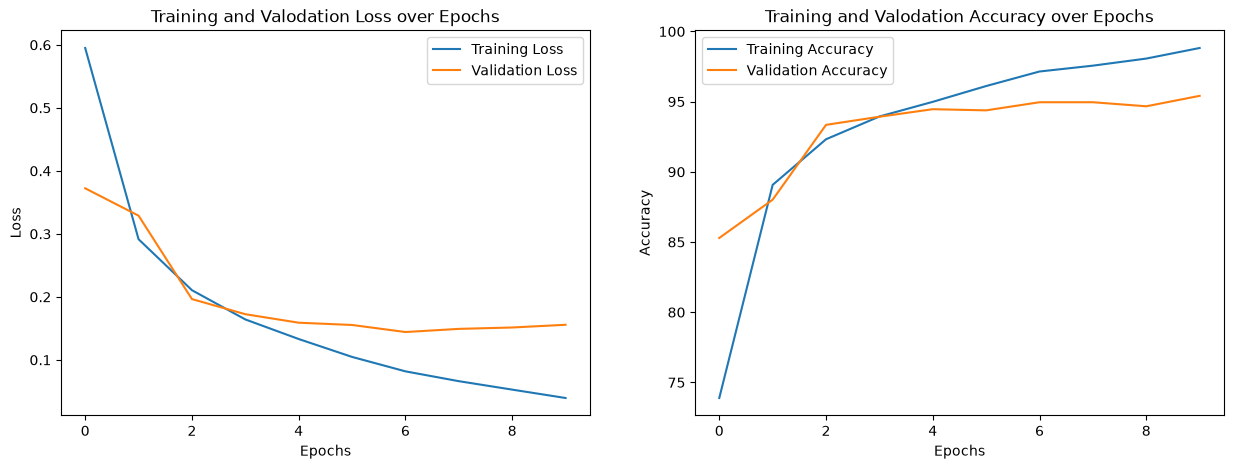

In [75]:
fig, axs = plt.subplots(nrows = 1, ncols = 2, figsize = (15,5))
axs[0].plot(total_loss_train_plot, label = "Training Loss")
axs[0].plot(total_loss_val_plot, label = "Validation Loss")
axs[0].set_title('Training and Valodation Loss over Epochs')
axs[0].set_xlabel('Epochs')
axs[0].set_ylabel('Loss')
axs[0].legend()

axs[1].plot(total_acc_train_plot, label = "Training Accuracy")
axs[1].plot(total_acc_val_plot, label = "Validation Accuracy")
axs[1].set_title('Training and Valodation Accuracy over Epochs')
axs[1].set_xlabel('Epochs')
axs[1].set_ylabel('Accuracy')
axs[1].legend()

plt.show()

# Working of Code
1) Reads the Image
2) Transform the image using the transform object created
3) Do the prediction process thorugh the model
4) inverse transform the label so as the know weather it is a Cat, Dog or a Wild Animal.

In [76]:
def predict_img(img_path):
    img = Image.open(img_path).convert('RGB')
    img = transform(img).unsqueeze(0).to(device)
    
    model.eval()
    with torch.no_grad():
        output = model(img)

    pred = torch.argmax(output, axis = 1).item()
    return label_encode.inverse_transform([pred])

In [84]:
predict_img('/Users/giridharj/Projects/Learning/Pytorch/Animal Faces/wild.jpeg')

array(['wild'], dtype=object)